<h1 style="text-align: center;">Programa3.Outliers</h1>

<p style="text-align: center;">23-09-2026</p>

<p style="text-align: center;">
    <img src="img/ITQ.png" width="500" alt="Logotipo del Instituto Tecnológico Quito">
</p>

# 3. Detección de outliers

**Nombre:** Nikolay Misael De La Cruz Melendres  
**Asignatura:** Fundamentos de Machine Learning  
**Docente:** Elvis David Pachacama Cabezas  
**Link Repositorio:** [NikolayDlc/fundamentosMachine](https://github.com/NikolayDlc/fundamentosMachine)

**Objetivo:** identificar valores atípicos mediante `EllipticEnvelope`, `IsolationForest` y el método del diagrama de caja y bigotes (RIC).

## 1. Importación de bibliotecas

- `pandas as pd`: carga y manipula tablas (`DataFrame`).
- `numpy as np`: operaciones con arreglos y búsqueda de posiciones.
- `scipy.stats`: estadísticas y percentiles.
- `EllipticEnvelope`: identifica observaciones inusuales considerando conjuntamente varias variables numéricas.
- `matplotlib.pyplot`: elabora las gráficas.

**Idea principal:** un *outlier* es una observación que se aparta del comportamiento habitual de los datos. No todo outlier es un error.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.covariance import EllipticEnvelope
import matplotlib.pyplot as plt

## 2. Cargar y explorar el dataset

`pd.read_csv("dataset/outliers.csv")` abre el archivo CSV del repositorio; la ruta es relativa a la carpeta desde la que se ejecuta JupyterLab (en esta práctica, `codigos`).

`df` es la tabla completa y `print(df)` permite inspeccionarla. El dataset utilizado en la práctica tiene **200 registros** y **dos atributos numéricos**, `a` y `b`.

**Para comprobarlo:** `df.shape` informa de filas y columnas; `df.head()` muestra los primeros registros.

In [2]:
# Carga de datos.
df = pd.read_csv("dataset/outliers.csv")
print(df)

            a         b
0    0.149014 -0.041479
1    0.194307  0.456909
2   -0.070246 -0.070241
3    0.473764  0.230230
4   -0.140842  0.162768
..        ...       ...
195 -5.114441  0.646251
196  5.631630  0.277174
197  1.552784  2.348984
198 -0.545507  1.530697
199  1.011772  4.813896

[200 rows x 2 columns]


## 3. Detección de outliers con `EllipticEnvelope`

Este método estima una región elíptica de observaciones habituales, apropiada sobre todo cuando la distribución de datos es aproximadamente elíptica.

- `support_fraction=None`: deja que el algoritmo determine automáticamente el tamaño del subconjunto utilizado para estimar la covarianza robusta.
- `contamination=0.25`: fija la proporción estimada de valores atípicos en **25 %**.
- `random_state=42`: fija una semilla para que el proceso aleatorio sea reproducible.
- `algorithm.fit(df)`: ajusta el detector a los datos.
- `predict(df)`: etiqueta las observaciones: **`1` = habitual** y **`-1` = atípica**.
- `np.where(df_outliers == -1)[0]`: recupera las **posiciones**, comenzando desde cero, de las filas marcadas como atípicas.
- `len(pos_outliers)`: cuenta cuántas posiciones se detectaron.

**Resultado mostrado en la práctica:** 50 observaciones señaladas como outliers por este método. Esto no demuestra por sí solo que el método sea mejor que otros, ya que el parámetro `contamination` influye en el resultado.

In [3]:
# Entrenamos un objeto de tipo EllipticEnvelope
algorithm = EllipticEnvelope(
    support_fraction=None,
    contamination=0.25,
    random_state=42
)

outlier_method = algorithm.fit(df)

# Aplicamos el método de detección de outliers
df_outliers = outlier_method.predict(df)
print(df_outliers)

# Determinar la posición de los outliers
pos_outliers = np.where(df_outliers == -1)[0]
print("\nOutliers en la posición:\n", pos_outliers)

# Determinar el número de outliers
print("\nNúmero de outliers:\n", len(pos_outliers))

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]

Outliers en la posición:
 [150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167
 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185
 186 187 188 189 190 191 192 193 194 195 196 197 198 199]

Número de outliers:
 50


## 4. Crear una función reutilizable: `find_outliers`

En lugar de escribir el mismo procedimiento para cada algoritmo, el profesor define una función que recibe:

- `df`: las variables que analizará el detector.
- `algorithm`: el método concreto que queremos probar.

**Procedimiento:** ajustar (`fit`), clasificar (`predict`), encontrar posiciones con `-1`, mostrar la cantidad y **devolver tanto las etiquetas como las posiciones** mediante `return`.

**Importante:** `fit()` aquí *entrena un detector de anomalías*, no un modelo que predice readmisiones hospitalarias.

In [4]:
# Función para detectar outliers con un algoritmo.

def find_outliers(df, algorithm):

    outlier_method = algorithm.fit(df)

    # Aplicamos el método entrenado.
    df_outliers = outlier_method.predict(df)

    print(df_outliers)

    # Determinamos las posiciones de los outliers.
    pos_outliers = np.where(df_outliers == -1)[0]

    print("\nOutliers en la posición:\n", pos_outliers)

    # Determinamos el número de outliers.
    print("\nNúmero de outliers:\n", len(pos_outliers))

    return df_outliers, pos_outliers

## 5. Método `IsolationForest` — práctica del PDF

`IsolationForest` detecta observaciones inusuales utilizando divisiones aleatorias de los datos: las observaciones aisladas con mayor facilidad tienden a ser más atípicas.

- `max_samples='auto'`: determina automáticamente cuántas observaciones usa cada árbol.
- `random_state=42`: permite repetir la generación aleatoria.
- `find_outliers(df, IF)`: reutiliza la función anterior, esta vez con `IsolationForest`.
- `len(pos_outliers)`: muestra nuevamente la cantidad encontrada.

La práctica también **importa** `OneClassSVM` y `LocalOutlierFactor`, pero no desarrolla esos algoritmos; por eso se mantienen como referencias, no como resultados ejecutados.

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

IF = IsolationForest(max_samples='auto', random_state=42)
# OC_SVM = ??  # No desarrollado en el material del profesor
# LOF = ??     # No desarrollado en el material del profesor

df_outliers, pos_outliers = find_outliers(df, IF)
print(len(pos_outliers))

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1  1 -1]

Outliers en la posición:
 [150 151 152 153 154 155 156 157 158 159 160 161 162 163 165 166 167 168
 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186
 187 188 189 190 191 192 193 194 195 196 197 199]

Número de outliers:
 48
48


## 6. Vista rápida de los registros

`df.head(10)` muestra las diez primeras filas para inspeccionar los valores de `a` y `b`. No modifica los datos.

In [6]:
df.head(10)

,a,b
0,0.149014,-0.041479
1,0.194307,0.456909
2,-0.070246,-0.070241
3,0.473764,0.230230
4,-0.140842,0.162768
5,-0.139025,-0.139719
6,0.072589,-0.573984
7,-0.517475,-0.168686
8,-0.303849,0.094274
9,-0.272407,-0.423691


## 7. Visualización de la frontera de decisión de `IsolationForest`

- `DecisionBoundaryDisplay.from_estimator(IF, df, response_method="decision_function")`: dibuja la función de decisión del detector ya ajustado sobre el plano de `a` y `b`.
- `scatter(...)`: superpone cada observación y la colorea según la etiqueta generada (`1` o `-1`).
- `plt.axis("square")`: usa la misma escala visual para los ejes del gráfico.
- `plt.show()`: muestra la figura.

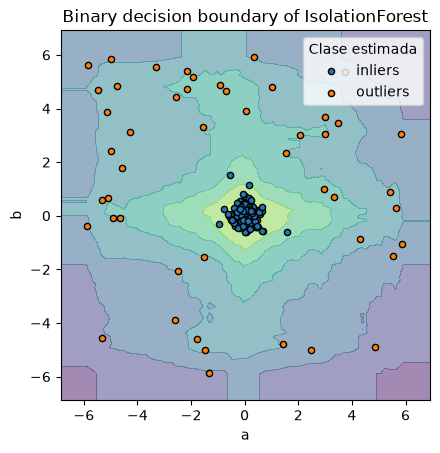

In [7]:
from sklearn.inspection import DecisionBoundaryDisplay

disp = DecisionBoundaryDisplay.from_estimator(
    IF,
    df,
    response_method="decision_function",
    alpha=0.5,
)

# CORRECCIÓN TÉCNICA de la leyenda de la gráfica del PDF:
mask_outliers = df_outliers == -1
mask_inliers = df_outliers == 1

disp.ax_.scatter(df.loc[mask_inliers, 'a'], df.loc[mask_inliers, 'b'],
                 s=20, edgecolor="k", label="inliers")
disp.ax_.scatter(df.loc[mask_outliers, 'a'], df.loc[mask_outliers, 'b'],
                 s=20, edgecolor="k", label="outliers")
disp.ax_.set_title("Binary decision boundary of IsolationForest")
plt.axis("square")
plt.legend(title="Clase estimada")
plt.show()

## 8. Filtrar observaciones habituales — ejercicio del PDF

`df[df_outliers == 1]` conserva las filas que `IsolationForest` marcó como habituales (`1`) y excluye las etiquetadas como atípicas (`-1`).

In [8]:
# Conservamos las filas clasificadas como habituales por IsolationForest
new_df = df[df_outliers == 1]
print(new_df)

            a         b
0    0.149014 -0.041479
1    0.194307  0.456909
2   -0.070246 -0.070241
3    0.473764  0.230230
4   -0.140842  0.162768
..        ...       ...
147  0.107105 -0.207873
148  0.269880  0.092190
149  0.243859  0.188889
164  1.582047 -0.618654
198 -0.545507  1.530697

[152 rows x 2 columns]


## 9. Método de caja y bigotes (*boxplot*) y rango intercuartílico

La práctica examina primero **una sola variable**, `a`:

- `Q1`: primer cuartil, percentil 25.
- `Q3`: tercer cuartil, percentil 75.
- `RIC = Q3 - Q1`: rango intercuartílico.
- `li = Q1 - 1.5 * RIC`: límite inferior.
- `ls = Q3 + 1.5 * RIC`: límite superior.
- `a < li` o `a > ls`: valores fuera de esos límites.
- `np.concatenate((pos_i, pos_s))`: une las posiciones de ambos extremos.

**Resultado:** límites aproximados de `-1.0853` y `1.0120`, con **44 observaciones atípicas en la variable `a`**. Este método es univariante, a diferencia de los anteriores aplicados conjuntamente a `a` y `b`.

Límite inferior: -1.0853060827395105
Límite superior: 1.0119554520872196
Posición de outliers: [150 153 154 157 159 160 162 165 168 169 171 172 174 175 177 178 181 184
 185 186 187 190 191 192 193 195 151 152 155 156 161 163 164 166 167 173
 176 179 180 182 188 189 196 197]
Número de outliers: 44


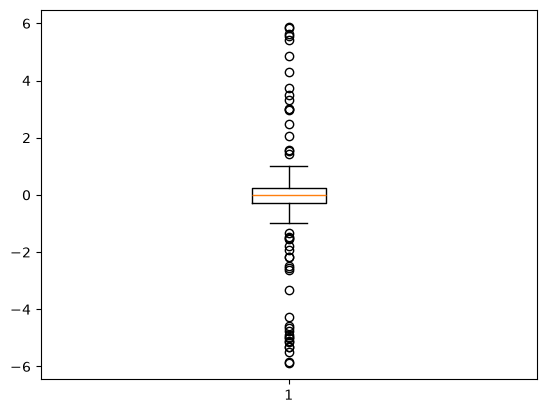

In [9]:
# Seleccionamos el atributo que vamos a medir
a = df['a']

# Seleccionamos los umbrales
Q1 = stats.scoreatpercentile(a, 25)
Q3 = stats.scoreatpercentile(a, 75)
RIC = Q3 - Q1
li = Q1 - 1.5 * RIC
ls = Q3 + 1.5 * RIC

print('Límite inferior:', li)
print('Límite superior:', ls)

# Buscamos las posiciones de los outliers
pos_i = np.where(a < li)[0]
pos_s = np.where(a > ls)[0]
pos_outliers = np.concatenate((pos_i, pos_s))
print('Posición de outliers:', pos_outliers)
print('Número de outliers:', len(pos_outliers))

# Dibujamos el diagrama de caja y bigotes (una sola vez)
prop = plt.boxplot(a)
plt.show()

## 10. Función de boxplot para cada columna

**Ampliación para que el ejercicio sea ejecutable:** completamos la función con los mismos cálculos de `Q1`, `Q3`, RIC y límites que acabamos de utilizar. La función devuelve las **posiciones de las filas atípicas de esa columna**.

In [10]:
# CORRECCIÓN TÉCNICA / AMPLIACIÓN: función incompleta en el PDF

def find_limits_BP(variable):
    Q1 = stats.scoreatpercentile(variable, 25)
    Q3 = stats.scoreatpercentile(variable, 75)
    RIC = Q3 - Q1
    li = Q1 - 1.5 * RIC
    ls = Q3 + 1.5 * RIC
    return np.where((variable < li) | (variable > ls))[0]

## 11. Detectar posiciones atípicas en todas las columnas

- `headers = df.columns`: recupera los nombres `a` y `b`.
- `for ...`: repite el cálculo para cada atributo.
- `find_limits_BP(variable)`: obtiene los índices atípicos según sus límites univariantes.
- `np.expand_dims(..., axis=1)`: convierte el arreglo de índices en una columna, como en el PDF.
- `np.vstack(...)`: reúne verticalmente los índices de ambas variables.
- `np.unique(...)`: elimina índices duplicados, porque una misma fila puede ser atípica en `a` y en `b`.

**Aclaración:** el total final corresponde a filas que son atípicas en **al menos una** de las dos variables. No se debe sumar directamente el conteo de cada columna porque puede haber coincidencias.

In [11]:
# Creamos un bucle for que estime los valores outliers de cada atributo
headers = df.columns
pos_outliers = []
for i in range(len(headers)):
    variable = df[headers[i]]
    pos_out = np.expand_dims(find_limits_BP(variable), axis=1)
    pos_outliers.append(pos_out)

# Concatenamos todas las posiciones de outliers
po = np.vstack(pos_outliers)
pos_out = np.unique(po)
print('Posiciones de outliers:', pos_out)
print('Número de outliers:', len(pos_out))

Posiciones de outliers: [104 150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166
 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184
 185 186 187 188 189 190 191 192 193 194 195 196 197 198 199]
Número de outliers: 51


## 12. Resumen para estudiar

| Método | Variables examinadas | Resultado mostrado en el PDF | Idea esencial |
|---|---|---:|---|
| `EllipticEnvelope` | `a` y `b` juntas | 50 | Región elíptica / covarianza robusta |
| `IsolationForest` | `a` y `b` juntas | 48 | Aislamiento por particiones aleatorias |
| `Boxplot` | Solo `a` | 44 | Límites basados en cuartiles y RIC |

**No comparar los números como una competición:** los métodos tienen criterios y parámetros distintos. Las cantidades anteriores son las que figuran en la práctica del profesor, no una evaluación de calidad de los detectores.

**Conexión con el dataset hospitalario:** allí revisaremos qué variables pueden presentar valores extremos y si estos son pacientes reales con situaciones clínicas poco frecuentes. En un proyecto predictivo, cualquier parámetro de un detector que aprenda de los datos debe ajustarse solo con entrenamiento, evitando utilizar indebidamente información de validación/test.

### Preguntas de repaso

1. ¿Qué diferencia existe entre un dato atípico y un dato incorrecto?
2. ¿Qué representan las etiquetas `1` y `-1`?
3. ¿Qué hace `fit(df)` y qué hace `predict(df)`?
4. ¿Por qué `EllipticEnvelope` encuentra 50 outliers cuando `contamination=0.25` en estos 200 registros?
5. ¿En qué se diferencia un método multivariante del boxplot sobre una sola columna?
6. ¿Para qué sirve `np.unique` al combinar las posiciones de outliers de varias columnas?